# **ANÁLISIS DE REGRESIÓN LINEAL SIMPLE (RLS)**

---

## **1. INTRODUCCIÓN Y ARQUITECTURA DEL APRENDIZAJE SUPERVISADO**

El Análisis de Regresión Lineal Simple (RLS) se sitúa dentro del marco del aprendizaje supervisado. En este esquema, el objetivo es mapear una variable de entrada $x$ hacia una variable de respuesta $y$ a través de una función aprendida a partir de datos.

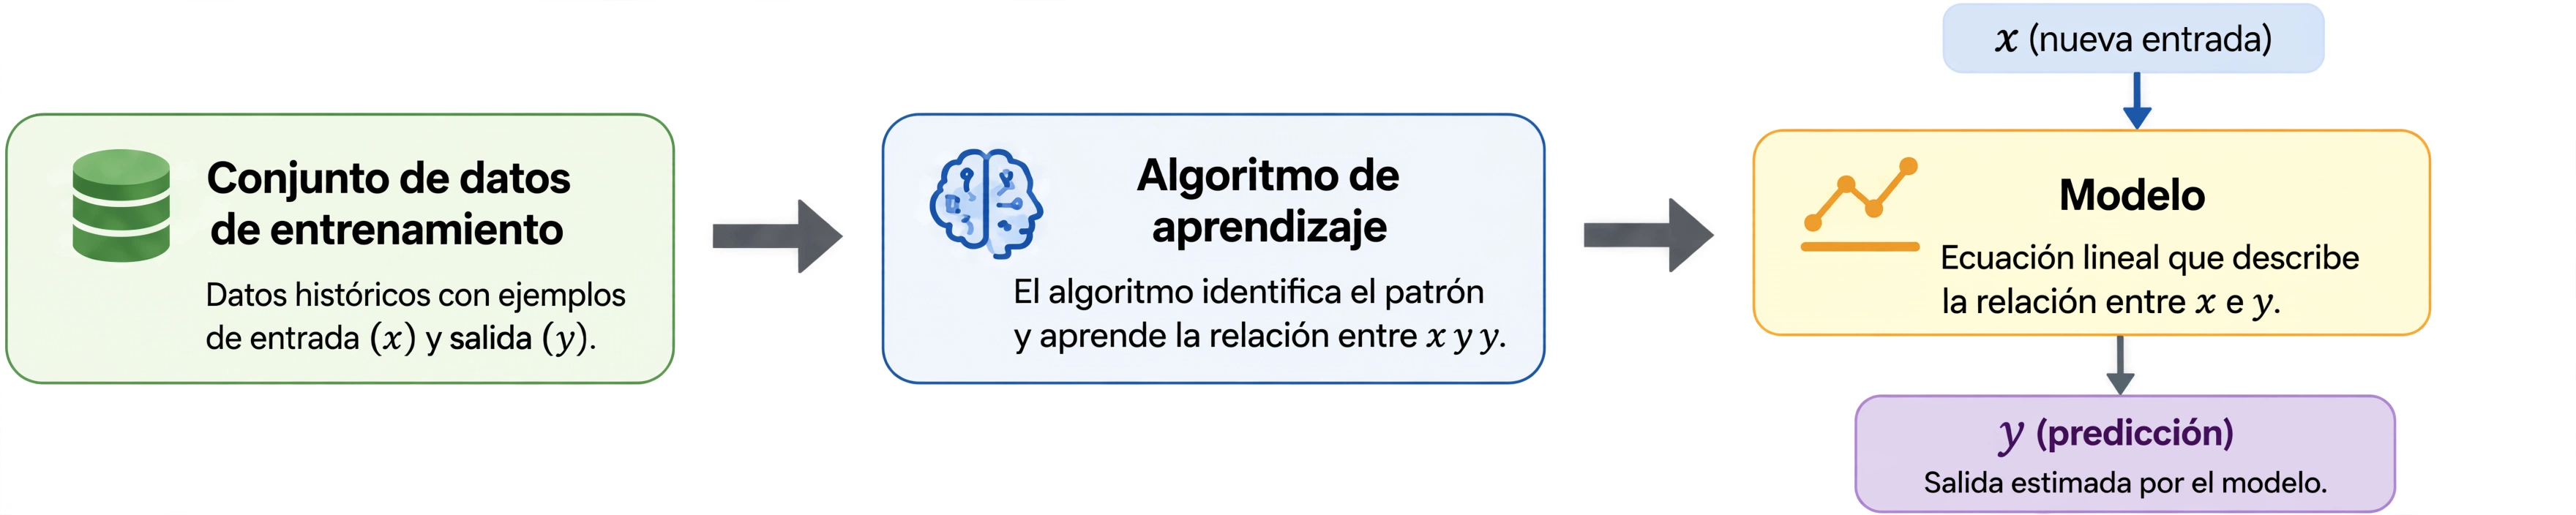

In [1]:
# ==============================================================================
# LIBRERÍAS DE MANIPULACIÓN Y CÁLCULO
# ==============================================================================
import numpy as np   # Álgebra lineal, vectores y funciones matemáticas
import pandas as pd  # Manipulación de DataFrames y lectura de archivos Excel
from IPython.display import display

# ==============================================================================
# LIBRERÍAS DE VISUALIZACIÓN GRÁFICA
# ==============================================================================
import matplotlib.pyplot as plt  # Creación de gráficos base y personalización de ejes
import seaborn as sns            # Gráficos estadísticos avanzados (heatmap, pairplot)

# ==============================================================================
# LIBRERÍAS DE INFERENCIA Y MODELADO ESTADÍSTICO
# ==============================================================================
import statsmodels.api as sm                         # Herramientas base de modelado OLS
import statsmodels.formula.api as smf                 # Sintaxis basada en fórmulas estilo R (y ~ x)
from statsmodels.stats.diagnostic import het_breuschpagan  # Prueba de Homocedasticidad de Breusch-Pagan
from statsmodels.stats.stattools import durbin_watson   # Prueba de autocorrelación de Durbin-Watson
from statsmodels.stats.outliers_influence import OLSInfluence # Distancia de Cook, Leverage, DFFITS, DFBETAS

# ==============================================================================
# PRUEBAS ESTADÍSTICAS Y MACHINE LEARNING
# ==============================================================================
from scipy import stats                                # Pruebas de Normalidad (Shapiro-Wilk, Jarque-Bera)
from sklearn.model_selection import train_test_split   # División aleatoria Train (80%) / Test (20%)
from sklearn.metrics import mean_squared_error, r2_score # Métricas de evaluación fuera de muestra (RMSE)

# Conectarse a Google Drive
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


# **Ejemplo 1**

> **Cargamos la base de datos**

In [3]:
ruta = ('/content/drive/MyDrive/Colab Notebooks/PulsoCardiacoMujeres.xlsx')
df_mujeres = pd.read_excel(ruta)
df_mujeres.head()

,Edad,Estatura,Peso,Cintura,Pulso
0,17,1.63,51.7,67.2,76
1,32,1.69,67.2,82.5,72
2,25,1.58,48.5,66.7,88
3,55,1.58,72.0,93.0,60
4,27,1.51,57.2,82.6,72


### **Limpieza y Análisis Preliminar**

* **Estructura de la base de datos**

In [4]:
print(df_mujeres.shape)
# Hay 40 observaciones y 5 variables.

(40, 5)


* **Identificación de Missing Values**

In [5]:
# Identificación de missing values
print(df_mujeres.isna().sum())
# No hay presencia de missing values.

Edad        0
Estatura    0
Peso        0
Cintura     0
Pulso       0
dtype: int64


* **Summary**

In [6]:
print(df_mujeres.describe().round(2))

        Edad  Estatura    Peso  Cintura  Pulso
count  40.00     40.00   40.00    40.00   40.0
mean   33.22      1.60   65.80    85.03   76.3
std    12.45      0.07   16.93    15.40   12.5
min    12.00      1.45   42.40    66.70   60.0
25%    23.00      1.56   53.12    73.42   68.0
50%    31.50      1.61   61.10    81.95   74.0
75%    41.00      1.65   73.32    94.38   80.0
max    59.00      1.73  115.20   126.50  124.0


3 observaciones

-

-

-

* **BoxPlot**

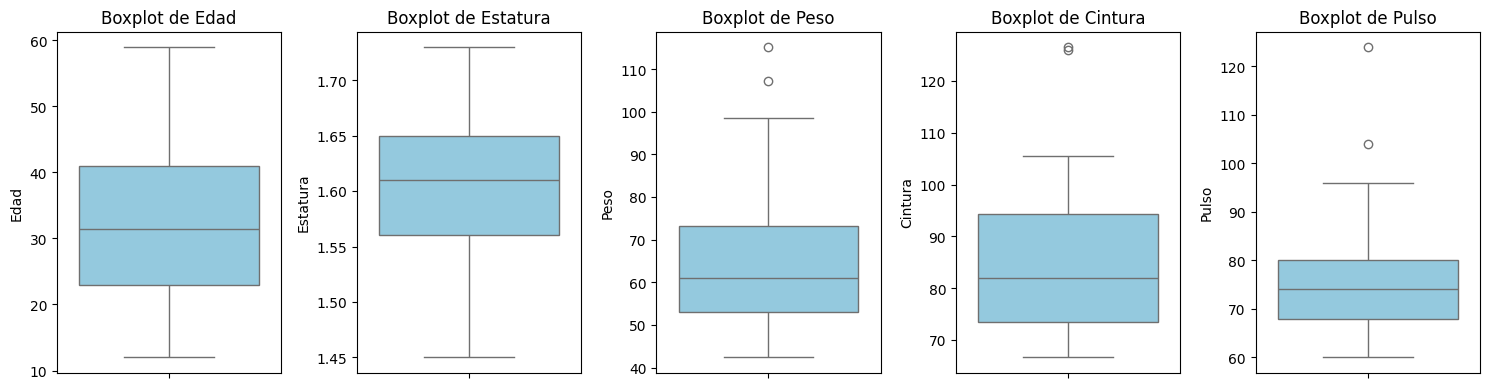

In [7]:
variables = ['Edad', 'Estatura', 'Peso', 'Cintura', 'Pulso']
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i, var in enumerate(variables):
    sns.boxplot(data=df_mujeres[var], ax=axes[i], color = 'skyblue')
    axes[i].set_title(f'Boxplot de {var}')
plt.tight_layout()
plt.show()

-

-

-

* **Identificación de Outliers**

In [8]:
# Diccionario para almacenar los índices de los outliers por variable
outliers_indices = {}

for var in variables:
    Q1 = df_mujeres[var].quantile(0.25)
    Q3 = df_mujeres[var].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Filtrar las filas que son outliers para la variable actual
    condicion_outlier = (df_mujeres[var] < limite_inferior) | (df_mujeres[var] > limite_superior)
    filas_outliers = df_mujeres[condicion_outlier]

    outliers_indices[var] = filas_outliers.index.tolist()

    print(f"=== OUTLIERS EN LA VARIABLE: {var} ===")
    if not filas_outliers.empty:
        print(f"Índices detectados: {filas_outliers.index.tolist()}")
        # .tolist(): Convierte ese objeto de tipo índice de Pandas en una lista estándar de Python (list).
        display(filas_outliers)
    else:
        print("No se encontraron outliers.")
    print("\n" + "="*50 + "\n")

=== OUTLIERS EN LA VARIABLE: Edad ===
No se encontraron outliers.


=== OUTLIERS EN LA VARIABLE: Estatura ===
No se encontraron outliers.


=== OUTLIERS EN LA VARIABLE: Peso ===
Índices detectados: [14, 21]


,Edad,Estatura,Peso,Cintura,Pulso
14,40,1.70,107.3,126.0,96
21,57,1.61,115.2,126.5,80




=== OUTLIERS EN LA VARIABLE: Cintura ===
Índices detectados: [14, 21]


,Edad,Estatura,Peso,Cintura,Pulso
14,40,1.70,107.3,126.0,96
21,57,1.61,115.2,126.5,80




=== OUTLIERS EN LA VARIABLE: Pulso ===
Índices detectados: [26, 38]


,Edad,Estatura,Peso,Cintura,Pulso
26,45,1.53,71.9,99.3,104
38,48,1.70,58.7,68.6,124


* **Matriz de Correlación y Mapa de Calor**

In [9]:
matriz_correlaciones = df_mujeres.corr(method='pearson').round(3)
display(matriz_correlaciones)

,Edad,Estatura,Peso,Cintura,Pulso
Edad,1.000,0.117,0.563,0.659,0.308
Estatura,0.117,1.000,0.361,0.189,0.208
Peso,0.563,0.361,1.000,0.921,0.143
Cintura,0.659,0.189,0.921,1.000,0.133
Pulso,0.308,0.208,0.143,0.133,1.000


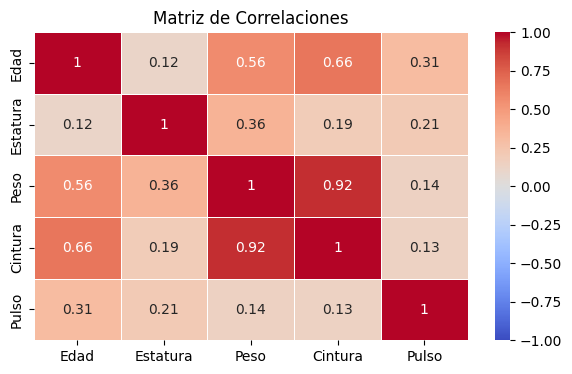

In [10]:
plt.figure(figsize=(7,4))
sns.heatmap(matriz_correlaciones,
            annot=True,
            cmap='coolwarm',
            linewidths=0.5,
            vmin = -1,
            vmax = 1)
plt.title('Matriz de Correlaciones')
plt.show()

-

-

-

* **Matriz de Dispersión**


---Matriz de Dispersión y Densidad---


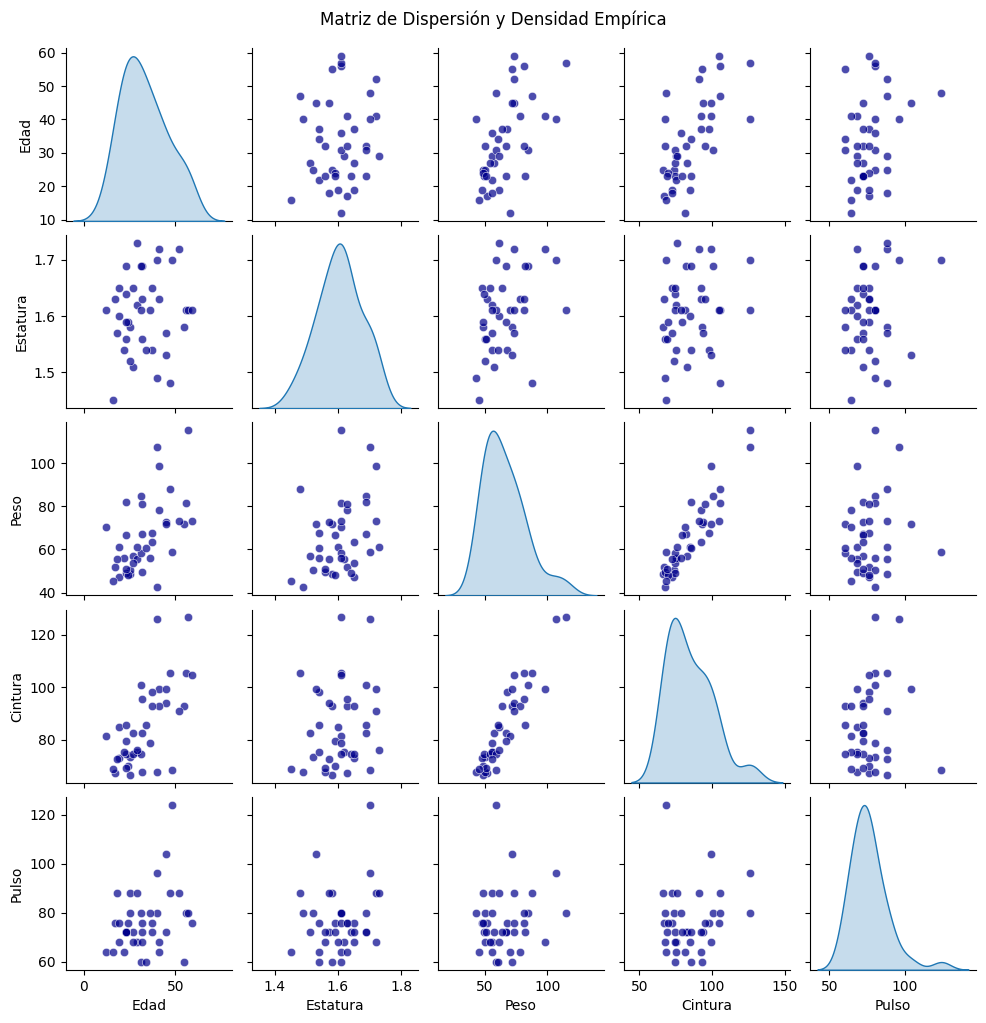

In [11]:
# Matriz de dispersión y densidad
df_mujeres_cuanti = df_mujeres.select_dtypes(include=[np.number])
sns.pairplot(df_mujeres_cuanti, diag_kind="kde", plot_kws={'color': 'darkblue', 'alpha': 0.7}, height=2)
plt.suptitle("Matriz de Dispersión y Densidad Empírica", y=1.02)
print('\n---Matriz de Dispersión y Densidad---')
plt.show()

## **Aplicación del Modelo de Regresión Lineal**

In [ ]:
# Dividimos la base de datos 80% entrenamiento y 20% prueba
train_df, test_df = train_test_split(df_mujeres,
                                     test_size=0.20,
                                     random_state=42,
                                     shuffle=True)

modelo = smf.ols(formula='Peso ~ Cintura', data=train_df).fit()
# .fit() para ajustar el modelo a los datos mediante el método de Mínimos Cuadrados Ordinarios (MCO).

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                   Peso   R-squared:                       0.858
Model:                            OLS   Adj. R-squared:                  0.854
Method:                 Least Squares   F-statistic:                     181.9
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           2.86e-14
Time:                        15:09:37   Log-Likelihood:                -106.49
No. Observations:                  32   AIC:                             217.0
Df Residuals:                      30   BIC:                             219.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -21.1863      6.608     -3.206      0.0

### **1. ECUACIÓN DEL MODELO Y INTERPRETACIONAL DE RESULTADOS (OLS)**

---

**Ecuación del Modelo Ajustado**

A partir de los coeficientes estimados por Mínimos Cuadrados Ordinarios (MCO / OLS), la ecuación muestral de regresión ajustada es:

$$\hat{Y}_i = \hat{\beta}_0 + \hat{\beta}_1 X_i$$

$$\hat{Y}_i = -21.1863 + 1.0326 X_i$$

En términos de las variables de estudio:

$$\widehat{\text{Peso}}_i = -21.1863 + 1.0326 \cdot \text{Cintura}_i$$

---

**Interpretación de Coeficientes y Parámetros del Modelo**

El p-valor de la variable **Cintura** y el intercepto son menores que el nivel de significancia $0.05$, indicando que son significativas para el modelo.

* **Intercepto ($\hat{\beta}_0 = -21.1863$):** Representa el valor promedio estimado para el $\text{Peso}$ cuando la variable $\text{Cintura} = 0$. Dado que un valor de medida de cintura igual a $0\text{ cm}$ no es físicamente posible en seres humanos. Cumple un rol matemático indispensable de ajuste de nivel para posicionar la recta en el plano.

* **Pendiente ($\hat{\beta}_1 = 1.0326$):** Por cada unidad adicional de incremento en la medida de la **Cintura** ($1\text{ cm}$), se espera que el **Peso** promedio de la persona se incremente en **$1.0326\text{ kg}$**. Se tiene un $95\%$ de confianza de que por cada unidad de incremento en la Cintura, el incremento real en el Peso se encuentra entre **$0.876\text{ kg}$** y **$1.189\text{ kg}$**.

---

**Bondad de Ajuste y Diagnósticos Principales**

* **Coeficiente de Determinación ($R^2 = 0.858$):** El $85.8\%$ de la variabilidad total del Peso es explicada linealmente por la medida de la **Cintura** a través del modelo ajustado. El $14.2\%$ restante corresponde a factores no observados o variabilidad aleatoria.

* El $R^2 \text{ ajustado} = 0.854$ confirma la solidez del modelo penalizando la escala de los grados de libertad.

* **Significancia Global del Modelo (Prueba $F$):** $F\text{-statistic} = 181.9$ ($p\text{-valor} = 2.86 \times 10^{-14} < 0.05$). Se rechaza categóricamente la hipótesis de que el predictor no aporta información al modelo. El modelo lineal en su conjunto es altamente explicativo.
---

**Diagnóstico de Normalidad e Independencia de Errores**
* **Jarque-Bera ($JB = 0.676$, $p\text{-valor} = 0.713 > 0.05$):** No existe evidencia suficiente para rechazar la hipótesis nula de normalidad en los residuos. Los errores se distribuyen de manera consistente con una distribución Normal ($\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$).
* **Durbin-Watson ($DW = 1.840$):** Al encontrarse un valor muy cercano a $2.0$, indica la **ausencia de autocorrelación de primer orden** en los errores, satisfaciendo el supuesto de independencia.

### **2. Gráfico de la Recta de Regresión**

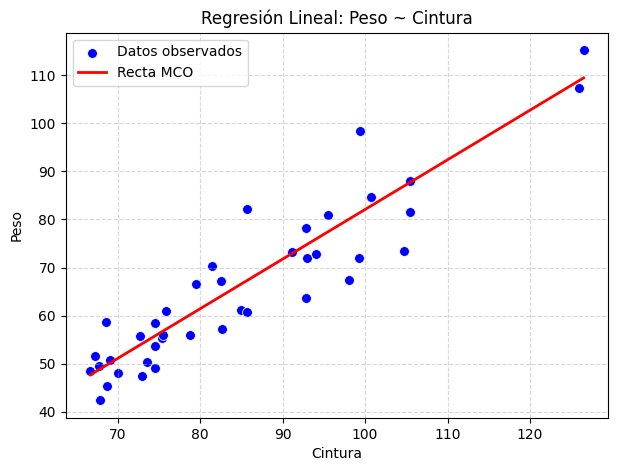

In [ ]:
# Calculamos los residuos del modelo.
residuos = modelo.resid

# Calculamos los valores ajustados por el modelo.
valores_ajustados = modelo.fittedvalues # Son las predicciones

# Realizamos el gráfico de dispersión de la base de datos completa.
plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=df_mujeres["Cintura"], y=df_mujeres["Peso"], color="blue", s=50, label="Datos observados"
)
# Agregamos la recta de regresión con los valores ajustados.
sns.lineplot(
    x=df_mujeres["Cintura"],
    y=valores_ajustados,
    color="red",
    linewidth=2,
    label="Recta MCO",
)

plt.title("Regresión Lineal: Peso ~ Cintura", fontsize=12)
plt.xlabel("Cintura")
plt.ylabel("Peso")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### **3. Análisis de los Errores (Supuestos de Gauss)**

> **La media de la distribución de probabilidad de e es cero**

In [ ]:
# Media de los Residuos
media_errores = np.mean(residuos).round(4)
print("---Media de los Residuos---")
print("La media de los residuos: ", media_errores)

---Media de los Residuos---
La media de los residuos:  0.0


> **La varianza de la distribución de probabilidad de e es constante**


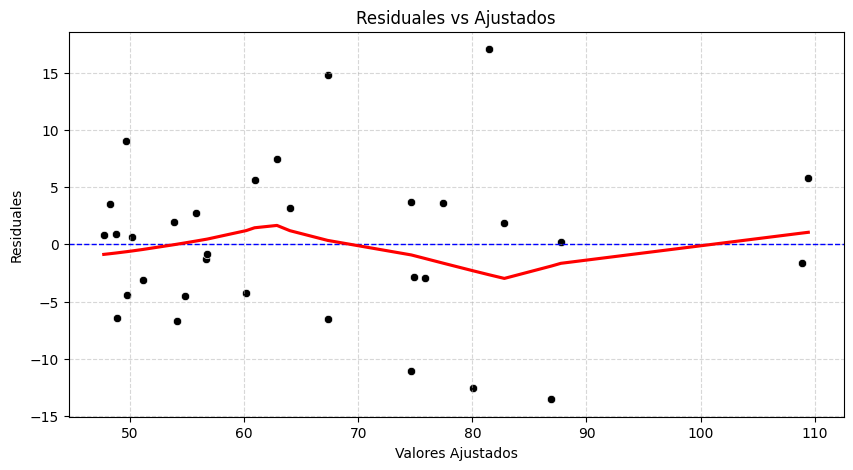

In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x=valores_ajustados, y=residuos, color="black")
plt.axhline(0, color="blue", linestyle="--", linewidth=1)

# Curva suavizada LOWESS
sns.regplot(
    x=valores_ajustados,
    y=residuos,
    scatter=False,
    lowess=True,
    color="red"
)

plt.title("Residuales vs Ajustados", fontsize=12)
plt.xlabel("Valores Ajustados")
plt.ylabel("Residuales")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

- En el gráfico de Residuos vs. Ajustados, se observa que la línea de tendencia roja se mantiene relativamente cerca del cero, validando de forma general el supuesto de linealidad.

- Sin embargo, se detecta una ligera apertura en la dispersión de los residuos a medida que aumentan los valores ajustados, lo que sugiere presencia de heterocedasticidad.

- Asimismo, el gráfico identifica algunas observaciones como los residuales de mayor magnitud, confirmando que son casos donde el modelo presenta un mayor error de estimación.

La Prueba de **Breusch-Pagan** es una prueba estadística que se utiliza para detectar la heterocedasticidad en un modelo de regresión lineal. La heterocedasticidad ocurre cuando la varianza de los errores o residuos no es constante a lo largo de las observaciones, lo que violaría una de las suposiciones básicas de los modelos de regresión lineal (homocedasticidad).

$$
\begin{cases}
H_0: \text{Varianza constante (Homocedasticidad)} \\
H_1: \text{Varianza no constante (Heterocedasticidad)}
\end{cases}
$$

In [ ]:
# Homocedasticidad (Breusch-Pagan)
estadistico_bp, p_value_bp, _, _ = het_breuschpagan(residuos, modelo.model.exog)
# exog (abreviatura de exogenous variables o variables exógenas) hace referencia a la matriz de diseño $X$.

print("\n---Homocedasticidad (Breusch-Pagan)---")
print("Estadístico de Prueba:", estadistico_bp.round(4), "|p-value:", p_value_bp.round(4))
print("Conclusión:", "No se rechaza H_0 (Hay Homocedasticidad)" if p_value_bp > 0.05
      else "Se rechaza H_0 (No Hay Homocedasticidad)")


---Homocedasticidad (Breusch-Pagan)---
Estadístico de Prueba: 1.981 |p-value: 0.1593
Conclusión: No se rechaza H_0 (Hay Homocedasticidad)


> **Los errores asociados con dos observaciones diferentes son independentes**

La prueba de **Durbin-Watson** evalúa si existe autocorrelación de primer orden en los residuos del modelo de regresión, es decir, si los errores están correlacionados entre sí (especialmente entre un error y el anterior).

$$
\begin{cases}
H_0: \text{No hay autocorrelación en los residuos (es decir, los residuos son independientes entre sí)} \\
H_1: \text{Sí hay autocorrelación en los residuos}
\end{cases}
$$

El estadístico de Durbin Watson toma valores entre 0 y 4:
  
  - DW ≈ 2 → No hay autocorrelación
  
  - DW < 2 → Autocorrelación positiva
  
  - DW > 2 → Autocorrelación negativa

In [ ]:
# Autocorrelación (Durbin-Watson)
dw_val = durbin_watson(residuos)
print("\n--- Autocorrelación (Durbin-Watson) ---")
print("Estadístico Durbin-Watson:", dw_val.round(4))
# Criterio práctico usual: valores entre 1.5 y 2.5 sugieren ausencia de autocorrelación
print("Conclusión:",("No se rechaza H_0 (No hay autocorrelación)" if 1.5 <= dw_val <= 2.5
        else "Se rechaza H_0 (Existe autocorrelación)"),)


--- Autocorrelación (Durbin-Watson) ---
Estadístico Durbin-Watson: 1.8402
Conclusión: No se rechaza H_0 (No hay autocorrelación)


> **La distribución de probabilidad de e es normal**


---Normalidad (Jarque-Bera)---
Estadístico de Prueba: 0.6762 |p-value: 0.7131
Conclusión: No se rechaza H_0 (Hay Normalidad)


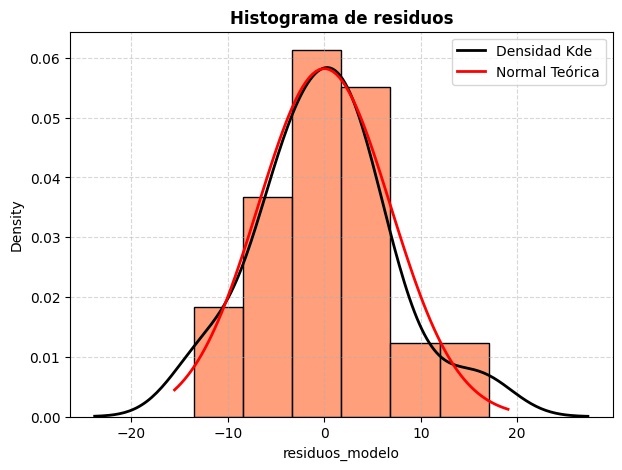

In [ ]:
# Normalidad (Jarque-Bera)
print("\n---Normalidad (Jarque-Bera)---")
estadistico_jb, p_value_jb = stats.jarque_bera(residuos)
print("Estadístico de Prueba:", estadistico_jb.round(4), "|p-value:", p_value_jb.round(4))
print("Conclusión:", ("No se rechaza H_0 (Hay Normalidad)" if p_value_jb > 0.05
      else "Se rechaza H_0 (No Hay Normalidad)"))

plt.figure(figsize=(7, 5))

# Histograma y curva de densidad Kde
sns.histplot(
    residuos,
    stat="density",
    color="coral",
    edgecolor="black",
    bins="sturges",
)
sns.kdeplot(residuos, color="black", linewidth=2, label="Densidad Kde")

# Curva Normal teórica ajustada (μ, σ)
x_norm = np.linspace(residuos.min() - 2, residuos.max() + 2, 100)
y_norm = stats.norm.pdf(x_norm, loc=residuos.mean(), scale=residuos.std())
plt.plot(x_norm, y_norm, color="red", linewidth=2, label="Normal Teórica")

plt.title("Histograma de residuos", fontsize=12, fontweight="bold")
plt.xlabel("residuos_modelo")
plt.ylabel("Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### **4. Predicciones**

In [ ]:
# Obtenemos las predicciones sobre el conjunto de prueba usando get_prediction()
predicciones_summary = modelo.get_prediction(test_df).summary_frame(alpha=0.05)
print(predicciones_summary.round(2))



     mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
19  87.76     2.01          83.66          91.86         72.95        102.57
16  55.75     1.46          52.76          58.73         41.21         70.28
15  55.75     1.46          52.76          58.73         41.21         70.28
26  81.36     1.66          77.97          84.74         66.73         95.98
4   64.11     1.24          61.57          66.65         49.66         78.56
12  66.59     1.23          64.07          69.10         52.14         81.04
37  57.19     1.41          54.32          60.06         42.68         71.71
27  72.89     1.32          70.19          75.59         58.40         87.37


- **mean:** Es el peso promedio predicho ($\hat{Y}$)

- **mean_se:** El error estándar de esa predicción media.

- **mean_ci_lower y mean_ci_upper:** Los límites inferior y superior del intervalo de confianza (usualmente al 95%) para el promedio del peso.

- **obs_ci_lower y obs_ci_upper:** Los límites inferior y superior del intervalo de predicción para una mujer en particular (un caso individual) y no para un promedio.

In [ ]:
# Guardamos las predicciones y los límites del intervalo de confianza en 'prueba'
test_df["predicted"] = predicciones_summary["mean"].values
test_df["lower"] = predicciones_summary["obs_ci_lower"].values
test_df["upper"] = predicciones_summary["obs_ci_upper"].values

# Visualizar el DataFrame de prueba con las nuevas columnas
display(test_df.round(2))

,Edad,Estatura,Peso,Cintura,Pulso,predicted,lower,upper
19,56,1.61,81.5,105.5,80,87.76,72.95,102.57
16,27,1.65,53.6,74.5,68,55.75,41.21,70.28
15,23,1.64,49.0,74.5,72,55.75,41.21,70.28
26,45,1.53,71.9,99.3,104,81.36,66.73,95.98
4,27,1.51,57.2,82.6,72,64.11,49.66,78.56
12,19,1.60,61.2,85.0,68,66.59,52.14,81.04
37,29,1.73,61.0,75.9,88,57.19,42.68,71.71
27,52,1.72,73.3,91.1,88,72.89,58.40,87.37


In [ ]:
# Error u observación residual en el conjunto de prueba
error_prueba = test_df["Peso"] - test_df["predicted"]

# Cálculo del RMSE
rmse_test = np.sqrt(np.mean(error_prueba**2))
print('RMSE: ', rmse_test.round(2))

# Calculamos el MAE
mae_test = np.mean(np.abs(error_prueba))
print('MAE: ', mae_test.round(2))

# Calculamos el MSE
mse_test = np.mean(error_prueba**2)
print('MSE: ', mse_test.round(2))

RMSE:  5.81
MAE:  5.14
MSE:  33.77


- **Interpretaciones:**

    * **MAE:** En promedio, las predicciones del modelo se alejan $5.14\text{ kg}$ del peso real de una persona.

    * **MSE:** El promedio de las desviaciones al cuadrado entre el peso real y el predicho es de $33.77\text{ kg}^2$.

    * **RMSE:** El error típico de predicción del modelo es de $5.81\text{ kg}$ al estimar el peso a partir de la circunferencia de la cintura.

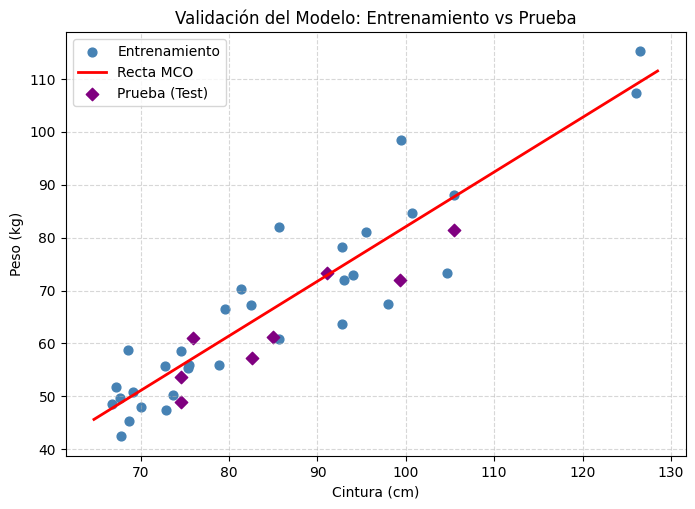

In [ ]:
# -------------------------------------------------------------------------
# Gráfico de Validación: Entrenamiento vs. Prueba
# -------------------------------------------------------------------------
plt.figure(figsize=(8, 5.5))

# Datos de entrenamiento (puntos azules)
plt.scatter(
    train_df["Cintura"],
    train_df["Peso"],
    color="steelblue",
    s=40,
    label="Entrenamiento"
)

# Recta de regresión del modelo
x_recta = np.linspace(
    df_mujeres["Cintura"].min() - 2, df_mujeres["Cintura"].max() + 2, 100
)
y_recta = modelo.predict(pd.DataFrame({"Cintura": x_recta}))
plt.plot(
    x_recta,
    y_recta,
    color="red",
    linewidth=2,
    label="Recta MCO"
)

# 3. Datos de prueba (puntos morados)
plt.scatter(
    test_df["Cintura"],
    test_df["Peso"],
    color="purple",
    marker="D",
    s=40,
    label="Prueba (Test)"
)

plt.title("Validación del Modelo: Entrenamiento vs Prueba", fontsize=12)
plt.xlabel("Cintura (cm)")
plt.ylabel("Peso (kg)")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

- **Interpretación Visual:** El gráfico muestra que los nuevos datos (puntos morados) siguen la trayectoria predicha por el modelo original. Esto confirma que la variable Cintura es un buen predictor para el Peso.

### **5. Diagnóstico de Influencia**

In [ ]:
# Obtenemos el diagnóstico de influencia del modelo
influencia = modelo.get_influence()

# Obtenemos todas las métricas de influencia
df_influencia = influencia.summary_frame()
display(df_influencia.round(2).head())

,dfb_Intercept,dfb_Cintura,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
39,-0.14,0.12,0.01,-0.66,0.06,-0.17,-0.65,-0.17
6,-0.10,0.08,0.01,-0.66,0.05,-0.15,-0.66,-0.14
25,-0.21,0.18,0.03,-0.95,0.07,-0.25,-0.95,-0.25
9,0.03,-0.02,0.00,0.13,0.07,0.03,0.13,0.03
13,0.05,0.02,0.08,2.16,0.03,0.39,2.31,0.42


In [ ]:
# Cálculo de Umbrales Teóricos
n = len(train_df)
p = modelo.df_model + 1  # Número de parámetros (incluyendo el intercepto, p = 2)

umbral_dffits = 2 * np.sqrt(p / n)
umbral_hat_sospechoso = 2 * (p / n)
umbral_hat_alto = 3 * (p / n)
umbral_student_resid = 2

print("\n--- UMBRALES DE EVALUACIÓN ---")
print("Umbral threshold:", round(umbral_dffits, 4))
print("Umbral Leverage Sospechoso:", round(umbral_hat_sospechoso, 4))
print("Umbral Leverage Alto:", round(umbral_hat_alto, 4))
print("Umbral Student Resid:", round(umbral_student_resid, 4))


--- UMBRALES DE EVALUACIÓN ---
Umbral threshold: 0.5
Umbral Leverage Sospechoso: 0.125
Umbral Leverage Alto: 0.1875
Umbral Student Resid: 2


In [ ]:
filtro_alertas = (
    (df_influencia["cooks_d"] > 0.5)
    | (df_influencia["hat_diag"] > umbral_hat_sospechoso)
    | (df_influencia["dffits"].abs() > umbral_dffits)
    | (df_influencia["student_resid"].abs() > umbral_student_resid)
)

# Desplegar solo las filas y columnas de interés directamente desde df_influencia
display(
    df_influencia.loc[
        filtro_alertas
    ].round(4)
)

,dfb_Intercept,dfb_Cintura,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
13,0.0539,0.0237,0.0753,2.1567,0.0314,0.3880,2.3068,0.4150
8,-0.3589,0.4616,0.1920,2.5189,0.0571,0.6197,2.7890,0.6862
24,0.4066,-0.4887,0.1762,-2.0240,0.0792,-0.5936,-2.1416,-0.6280
21,-0.4541,0.4987,0.1433,0.9488,0.2415,0.5354,0.9471,0.5345
14,0.1241,-0.1364,0.0111,-0.2673,0.2365,-0.1487,-0.2631,-0.1464


**Diagnóstico e Interpretación de Observaciones Influyentes**

---

**1. Resumen Diagnóstico**

Se identificaron **5 observaciones de interés: 13, 8, 24, 21 y 14**.

* Ninguna observación supera el umbral crítico de la Distancia de Cook ($D_i > 0.5$). El valor máximo alcanzado es $D_8 = 0.1920$. Esto garantiza que **ningún dato individual distorsiona o invalida severamente el modelo global de regresión**.
* Las observaciones se clasifican entre *outliers* y puntos con alto *leverage* en la variable predictora ($X = \text{Cintura}$).

---

**2. Análisis Detallado por Observación**

**Observación 13:**
* **Métricas Clave:** Métricas clave: student_resid = $2.3068$ | hat_diag = $0.0314$ | cooks_d = $0.0753$ | dffits = $0.4150$

  * **hat_diag = $0.0314$:** Esta mujer tiene una medida de cintura muy cercana al promedio del grupo (hat_diag bajo), por lo que no tiene poder de palanca para inclinar la recta de regresión.

  * **student_resid = $2.3068$:** Rebasa ligeramente el límite de $2$. Esto significa que su peso real es moderadamente más alto de lo que el modelo predice para su cintura (outlier leve en la respuesta).   

  * **Impacto Global:** Como su apalancamiento es mínimo, su Distancia de Cook ($0.075$) y su DFFITS ($0.415$) están muy por debajo de los umbrales. No altera de forma grave el modelo global.

* **Efecto al remover la Observación 13:**
  * **Intercepto (`dfb_Intercept` = $0.0539$):** El valor de $\hat{\beta}_0$ **disminuirá**.
  $\beta_{0(actual)}=\beta_{0(anterior)}-(dfbIntercept*SE_{\beta_0}) = -21.1863-(0.0539*6.608)=-21.5425$
  * **Pendiente (`dfb_Cintura` = $0.0237$):** La pendiente de Cintura **disminuirá** en aprox. $0.0237$ errores estándar.
  $\beta_{1(actual)}=\beta_{1(anterior)}-(dfb.Cntr*SE_{\beta_1}) = 1.0326-(0.0237*0.077)=1.0308$

---

**Observación 8: Outlier Severo en Peso (Bajo Leverage, Alta Respuesta)**
* **Métricas Clave:** student_resid = $2.7890$ | hat_diag = $0.0571$ | cooks_d = $0.1920$ | dffits = $0.6862$.
  * **hat_diag = $0.0571$:** Presenta un apalancamiento bajo, lo que indica que su cintura se encuentra dentro de la zona central y común de la muestra.   
  * **student_resid = $2.7890$:** Esto revela que se trata de un outlier severo en peso: la mujer pesa considerablemente más de lo esperado para su medida de cintura.   
  * Aunque su peso es inusual, su Distancia de Cook ($0.192$) está lejos del umbral crítico de $0.5$. Eliminarla cambiaría de forma muy leve los coeficientes.

* **Efecto al remover la Observación 8:**
  * **Intercepto (`dfb_Intercept` = $-0.3589$):** El valor de $\hat{\beta}_0$ **aumentará**.
  $\beta_{0(actual)}=\beta_{0(anterior)}-(dfbIntercept*SE_{\beta_0}) = -21.1863-(-0.3589*6.608)=-18.8147$
  * **Pendiente (`dfb_Cintura` = $0.4616$):** La pendiente de Cintura **disminuirá** en aprox. $0.46$ errores estándar.
  $\beta_{1(actual)}=\beta_{1(anterior)}-(dfb.Cntr*SE_{\beta_1}) = 1.0326-(0.4616*0.077)=0.9971$

---

**Observación 24: Outlier Severo en Peso (Bajo Leverage, Baja Respuesta)**
* **Métricas Clave:** student_resid = $-2.1416$ | hat_diag = $0.0792$ | cooks_d = $0.1762$ | dffits = $-0.6280$.
  * **hat_diag = $0.0792$:** Al igual que los casos anteriores, posee un apalancamiento bajo ($0.079$), encontrándose en la zona habitual de cinturas.   
  * **student_resid = $-2.1416$:** En este caso, el desvío es opuesto al de la observación 8: se trata de una mujer cuyo peso real es notablemente más bajo del que pronostica el modelo para su cintura.
  * Su Distancia de Cook ($0.176$) indica una influencia leve sobre los parámetros globales. No distorsiona la pendiente de manera drástica, sino que refleja un punto con un error de predicción acentuado hacia la baja.   

* **Efecto al remover la Observación 24:**
  * **Intercepto (`dfb_Intercept` = $0.4066$):** El intercepto $\hat{\beta}_0$ **disminuirá**.
  $\beta_{0(actual)}=\beta_{0(anterior)}-(dfbIntercept*SE_{\beta_0}) = -21.1863-(0.4066*6.608)=-23.8731$
  * **Pendiente (`dfb_Cintura` = $-0.4887$):** La pendiente de Cintura $\hat{\beta}_1$ **aumentará** significativamente (alrededor de $0.49$ errores estándar).
  $\beta_{1(actual)}=\beta_{1(anterior)}-(dfb.Cntr*SE_{\beta_1}) = 1.0326-(-0.4887*0.077)=1.0702$

---

**Observación 21: Alto Apalancamiento con Influencia Moderada**
* **Métricas Clave:** student_resid = $0.9471$ | hat_diag = $0.2415$ | cooks_d = $0.1433$ | dffits = $0.5345$
  * **hat_diag= $0.2415:$** Indica un apalancamiento alto (está muy alejada del promedio de las cinturas del grupo, situada en un extremo de la distribución). Funciona como una "palanca larga".
  * **student_resid = $0.9471$:** Su residuo estudentizado está dentro de la normalidad (|residual| < 2), es decir, su peso guarda una relación coherente y lógica con su cintura extrema.
  * Aunque su Distancia de Cook ($0.143$) y su DFFITS ($0.535$) son moderados porque su peso acompaña a su cintura, al estar en la orilla ejerce presión sobre la pendiente. Si se removiera, podría ajustar ligeramente la inclinación de la recta debido a su posición aislada en el eje horizontal.

---

**Observación 14: Alto Apalancamiento Puro Sin Influencia (Dato Inofensivo)**
* **Métricas Clave:** student_resid = $-0.2631$ | hat_diag = $0.2365$ | cooks_d = $0.0111$ | dffits = $-0.1464$.
  * **hat_diag = $0.2365$:** Presenta un apalancamiento alto, lo que significa que también se localiza en los extremos de la variable predictora (cintura muy atípica o apartada del promedio).
  * **student_resid = $-0.2631$:** Demuestra que su peso es totalmente coherente con su medida de cintura. Sigue de manera casi perfecta la tendencia general del modelo.
  * Puesto que el punto es extremadamente congruente con la tendencia de la línea de regresión, su Distancia de Cook es casi nula ($0.011$). A pesar de tener palanca alta, no deforma ni arrastra al modelo porque su peso "pesa" en la dirección correcta de la tendencia.

---


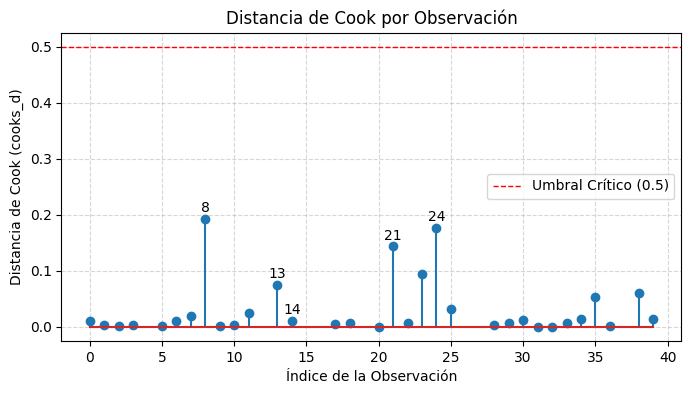

In [ ]:
plt.figure(figsize=(8, 4))

plt.stem(
    df_influencia.index,
    df_influencia["cooks_d"]
)

plt.axhline(
    y=0.5,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Umbral Crítico (0.5)"
)

# Etiquetar las observaciones filtradas por la máscara booleana
for i in df_influencia[filtro_alertas].index:
    plt.annotate(
        str(i),
        (i, df_influencia.loc[i, "cooks_d"]),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center"
    )

plt.title("Distancia de Cook por Observación", fontsize=12)
plt.xlabel("Índice de la Observación")
plt.ylabel("Distancia de Cook (cooks_d)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

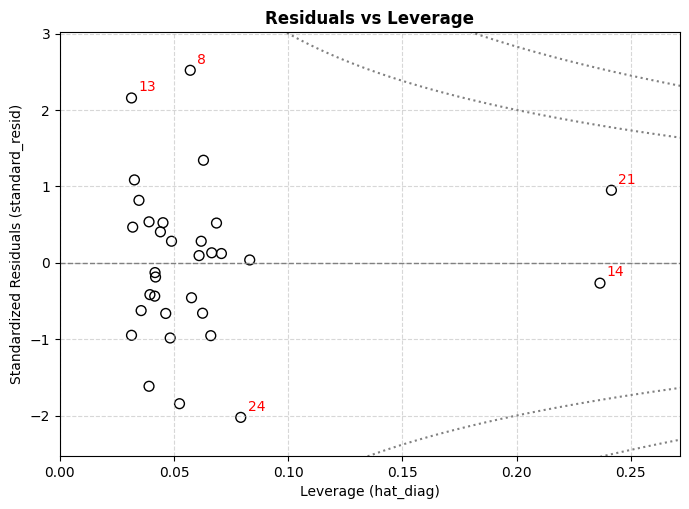

In [ ]:
plt.figure(figsize=(8, 5.5))

# Usar directamente hat_diag y standard_resid de df_influencia
plt.scatter(
    df_influencia["hat_diag"],
    df_influencia["standard_resid"],
    color="black",
    facecolors="none",
    s=50,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)

# Resaltar puntos particulares (ejemplo: observaciones 2, 13 y 26)
puntos_interes = [13, 8, 24, 21, 14]
for i in puntos_interes:
    if i in df_influencia.index:
        plt.annotate(
            str(i),
            (df_influencia.loc[i, "hat_diag"], df_influencia.loc[i, "standard_resid"]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=10,
            color="red",
        )

# Curvas teóricas de Distancia de Cook (0.5 y 1.0)
x_grid = np.linspace(0.001, df_influencia["hat_diag"].max() + 0.05, 100)
for cook_val in [0.5, 1.0]:
    y_cook = np.sqrt(cook_val * p * (1 - x_grid) / x_grid)
    plt.plot(
        x_grid,
        y_cook,
        color="gray",
        linestyle=":",
        label=f"Cook D={cook_val}" if cook_val == 0.5 else "",
    )
    plt.plot(x_grid, -y_cook, color="gray", linestyle=":")

plt.ylim(
    df_influencia["standard_resid"].min() - 0.5,
    df_influencia["standard_resid"].max() + 0.5,
)
plt.xlim(0, df_influencia["hat_diag"].max() + 0.03)

plt.title("Residuals vs Leverage", fontsize=12, fontweight="bold")
plt.xlabel("Leverage (hat_diag)")
plt.ylabel("Standardized Residuals (standard_resid)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

-  Eje X (Leverage): qué tan extremo es el valor de la cintura comparado con las demás (valores extremos de cintura → más a la derecha).

- Eje Y (Residuos estandarizados): cuán alejado está el valor real del peso respecto al valor predicho por el modelo.

- Líneas curvas grises: representan niveles de la distancia de Cook (cook.d). Si un punto está cerca o sobre las curvas, está influyendo en los coeficientes del modelo.

- El punto 21 presenta un leverage alto, lo que indica que su valor de cintura es considerablemente diferente al del resto de las observaciones. Además, su residuo estandarizado (casi 1.0), aunque no extremo, en combinación con su posición cercada a la curva de distancia de Cook (0.5) sugiere que esta observación tiene un impacto potencial en los coeficientes del modelo.

- El punto 8 tiene un residuo estandarizado elevado, lo que indica que el modelo subestima en gran medida el peso de esta observación respecto al valor real. Sin embargo, su leverage es bajo, lo que implica que su valor de cintura no se desvía mucho del promedio de la muestra. Por tanto, aunque el modelo comete un error importante con esta observación, no tiene un impacto significativo en la estimación de los coeficientes.

- El punto 24 presenta un residuo estandarizado negativo considerable, lo que indica que el modelo sobreestima el peso real de la observación. No obstante, su leverage es bajo, lo que significa que su valor de cintura se encuentra dentro del rango común del resto de los datos.

In [ ]:
# Veamos la información de las observaciones 13, 8, 24, 21 y 14
train_df.loc[[13,8,24,21,14]]

,Edad,Estatura,Peso,Cintura,Pulso
13,23,1.69,82.1,85.7,72
8,41,1.72,98.5,99.4,68
24,59,1.61,73.4,104.7,76
21,57,1.61,115.2,126.5,80
14,40,1.70,107.3,126.0,96


### **Modelo 2 (Sin observación 21)**

In [ ]:
# Eliminar la fila 21 por su índice (axis=0)
entrenamiento_sin_21 = train_df.drop(index=21)
len(entrenamiento_sin_21)

31

In [ ]:
modelo2 = smf.ols(formula='Peso ~ Cintura', data=entrenamiento_sin_21).fit()
print(modelo2.summary())

                            OLS Regression Results                            
Dep. Variable:                   Peso   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.813
Method:                 Least Squares   F-statistic:                     131.6
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           2.69e-12
Time:                        15:10:45   Log-Likelihood:                -103.18
No. Observations:                  31   AIC:                             210.4
Df Residuals:                      29   BIC:                             213.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -18.1806      7.340     -2.477      0.0

**Ecuación del Modelo Ajustado**

A partir de los coeficientes estimados por Mínimos Cuadrados Ordinarios (MCO / OLS), la ecuación muestral de regresión ajustada es:

$$\hat{Y}_i = \hat{\beta}_0 + \hat{\beta}_1 X_i$$

$$\hat{Y}_i = -18.1806 + 0.9944 X_i$$

---

**Interpretación de Coeficientes y Parámetros del Modelo**

El p-valor de la variable **Cintura** y el intercepto son menores que el nivel de significancia $0.05$, indicando que son significativas para el modelo.

* **Intercepto ($\hat{\beta}_0 = -18.1806$):** Representa el valor promedio estimado para el $\text{Peso}$ cuando la variable $\text{Cintura} = 0$. Dado que un valor de medida de cintura igual a $0\text{ cm}$ no es físicamente posible en seres humanos. Cumple un rol matemático indispensable de ajuste de nivel para posicionar la recta en el plano.

* **Pendiente ($\hat{\beta}_1 = 0.9944$):** Por cada unidad adicional de incremento en la medida de la **Cintura** ($1\text{ cm}$), se espera que el **Peso** promedio de la persona se incremente en **$0.9944\text{ kg}$**. Se tiene un $95\%$ de confianza de que por cada unidad de incremento en la Cintura, el incremento real en el Peso se encuentra entre **$0.817\text{ kg}$** y **$1.172\text{ kg}$**.

---

**Bondad de Ajuste y Diagnósticos Principales**

* **Coeficiente de Determinación ($R^2 = 0.819$):** El $81.9\%$ de la variabilidad total del Peso es explicada linealmente por la medida de la **Cintura** a través del modelo ajustado. El $18.1\%$ restante corresponde a factores no observados o variabilidad aleatoria.

* El $R^2 \text{ ajustado} = 0.813$ confirma la solidez del modelo penalizando la escala de los grados de libertad.

* **Significancia Global del Modelo (Prueba $F$):** $F\text{-statistic} = 131.6$ ($p\text{-valor} = 2.69e-12 < 0.05$). Se rechaza categóricamente la hipótesis de que el predictor no aporta información al modelo. El modelo lineal en su conjunto es altamente explicativo.
---

**Diagnóstico de Normalidad e Independencia de Errores**
* **Jarque-Bera ($JB = 1.156$, $p\text{-valor} = 0.458 > 0.05$):** No existe evidencia suficiente para rechazar la hipótesis nula de normalidad en los residuos. Los errores se distribuyen de manera consistente con una distribución Normal ($\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$).
* **Durbin-Watson ($DW = 1.893$):** Al encontrarse un valor muy cercano a $2.0$, indica la **ausencia de autocorrelación de primer orden** en los errores, satisfaciendo el supuesto de independencia.

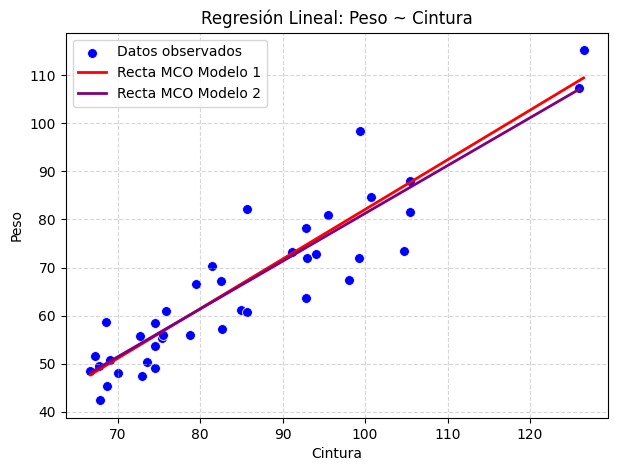

In [ ]:
residuos2 = modelo2.resid
valores_ajustados2 = modelo2.fittedvalues

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x=df_mujeres["Cintura"], y=df_mujeres["Peso"], color="blue", s=50, label="Datos observados"
)

sns.lineplot(
    x=df_mujeres["Cintura"],
    y=valores_ajustados,
    color="red",
    linewidth=2,
    label="Recta MCO Modelo 1",
)

sns.lineplot(
    x=df_mujeres["Cintura"],
    y=valores_ajustados2,
    color="purple",
    linewidth=2,
    label="Recta MCO Modelo 2",
)

plt.title("Regresión Lineal: Peso ~ Cintura", fontsize=12)
plt.xlabel("Cintura")
plt.ylabel("Peso")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

> **La media de la distribución de probabilidad de e es cero**

In [ ]:
# Media de los Residuos
print("---Media de los Residuos---")
print("La media de los residuos: ", np.mean(residuos2).round(4))

---Media de los Residuos---
La media de los residuos:  0.0


> **La varianza de la distribución de probabilidad de e es constante**

In [ ]:
# Homocedasticidad (Breusch-Pagan)
estadistico_bp, p_value_bp, _, _ = het_breuschpagan(residuos2, modelo2.model.exog)
print("\n---Homocedasticidad (Breusch-Pagan)---")
print("Estadístico de Prueba:", estadistico_bp.round(4), "|p-value:", p_value_bp.round(4))
print("Conclusión:", "No se rechaza H_0 (Hay Homocedasticidad)" if p_value_bp > 0.05
      else "Se rechaza H_0 (No Hay Homocedasticidad)")


---Homocedasticidad (Breusch-Pagan)---
Estadístico de Prueba: 2.4111 |p-value: 0.1205
Conclusión: No se rechaza H_0 (Hay Homocedasticidad)


> **Los errores asociados con dos observaciones diferentes son independentes**

In [ ]:
# Autocorrelación (Durbin-Watson)
dw_val = durbin_watson(residuos2)
print("\n--- Autocorrelación (Durbin-Watson) ---")
print("Estadístico Durbin-Watson:", dw_val.round(4))
# Criterio práctico usual: valores entre 1.5 y 2.5 sugieren ausencia de autocorrelación
print("Conclusión:",("No se rechaza H_0 (No hay autocorrelación)" if 1.5 <= dw_val <= 2.5
        else "Se rechaza H_0 (Existe autocorrelación)"),)


--- Autocorrelación (Durbin-Watson) ---
Estadístico Durbin-Watson: 1.8927
Conclusión: No se rechaza H_0 (No hay autocorrelación)


> **La distribución de probabilidad de e es normal**

In [ ]:
# Normalidad (Jarque-Bera)
print("\n---Normalidad (Jarque-Bera)---")
estadistico_jb, p_value_jb = stats.jarque_bera(residuos2)
print("Estadístico de Prueba:", estadistico_jb.round(4), "|p-value:", p_value_jb.round(4))
print("Conclusión:", ("No se rechaza H_0 (Hay Normalidad)" if p_value_jb > 0.05
      else "Se rechaza H_0 (No Hay Normalidad)"))


---Normalidad (Jarque-Bera)---
Estadístico de Prueba: 1.5607 |p-value: 0.4583
Conclusión: No se rechaza H_0 (Hay Normalidad)


> **Predicciones**

In [ ]:
# Obtenemos las predicciones sobre el conjunto de prueba usando get_prediction()
predicciones_summary2 = modelo2.get_prediction(test_df).summary_frame(alpha=0.05)
print(predicciones_summary2.round(2))

# Guardamos las predicciones y los límites del intervalo de confianza en 'prueba'
test_df["predicted"] = predicciones_summary2["mean"].values
test_df["lower"] = predicciones_summary2["obs_ci_lower"].values
test_df["upper"] = predicciones_summary2["obs_ci_upper"].values

# Visualizar el DataFrame de prueba con las nuevas columnas
display(test_df.round(2))

     mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
19  86.73     2.29          82.05          91.41         71.71        101.75
16  55.90     1.47          52.89          58.92         41.31         70.49
15  55.90     1.47          52.89          58.92         41.31         70.49
26  80.56     1.86          76.76          84.37         65.79         95.34
4   63.96     1.26          61.39          66.52         49.45         78.46
12  66.34     1.26          63.76          68.92         51.84         80.85
37  57.29     1.41          54.40          60.18         42.73         71.86
27  72.41     1.42          69.51          75.31         57.84         86.97


,Edad,Estatura,Peso,Cintura,Pulso,predicted,lower,upper
19,56,1.61,81.5,105.5,80,86.73,71.71,101.75
16,27,1.65,53.6,74.5,68,55.90,41.31,70.49
15,23,1.64,49.0,74.5,72,55.90,41.31,70.49
26,45,1.53,71.9,99.3,104,80.56,65.79,95.34
4,27,1.51,57.2,82.6,72,63.96,49.45,78.46
12,19,1.60,61.2,85.0,68,66.34,51.84,80.85
37,29,1.73,61.0,75.9,88,57.29,42.73,71.86
27,52,1.72,73.3,91.1,88,72.41,57.84,86.97


In [ ]:
# Error u observación residual en el conjunto de prueba
error_prueba2 = test_df["Peso"] - test_df["predicted"]

# Cálculo del MAE
mae_test2 = np.mean(np.abs(error_prueba2))
print('MAE: ', mae_test2.round(2))

# Cálculo del MSE
mse_test2 = np.mean(error_prueba2**2)
print('MSE: ', mse_test2.round(2))

# Cálculo del RMSE
rmse_test2 = np.sqrt(np.mean(error_prueba2**2))
print('RMSE: ', rmse_test2.round(2))

MAE:  4.95
MSE:  30.24
RMSE:  5.5


- **Interpretaciones:**

    * **MAE:** En promedio, las predicciones del modelo se alejan $4.95\text{ kg}$ del peso real de una persona.

    * **MSE:** El promedio de las desviaciones al cuadrado entre el peso real y el predicho es de $30.24\text{ kg}^2$.

    * **RMSE:** El error típico de predicción del modelo es de $5.5\text{ kg}$ al estimar el peso a partir de la circunferencia de la cintura.

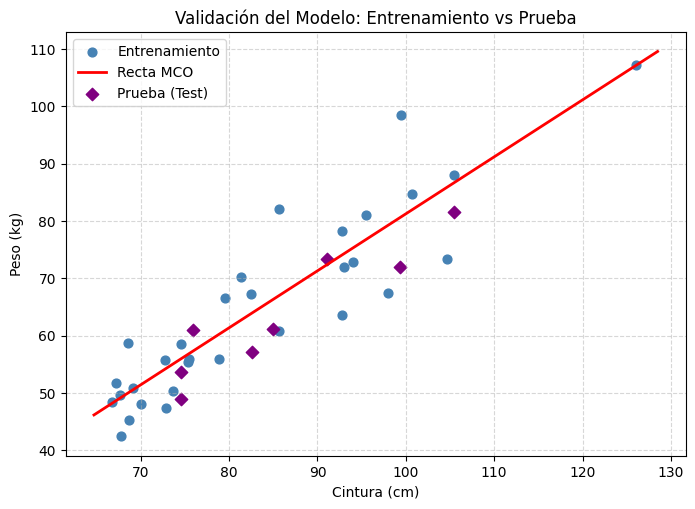

In [ ]:
# Gráfico de Validación: Entrenamiento vs. Prueba
# -------------------------------------------------------------------------
plt.figure(figsize=(8, 5.5))

# Datos de entrenamiento (puntos azules)
plt.scatter(
    entrenamiento_sin_21["Cintura"],
    entrenamiento_sin_21["Peso"],
    color="steelblue",
    s=40,
    label="Entrenamiento"
)

# Recta de regresión del modelo
x_recta = np.linspace(
    df_mujeres["Cintura"].min() - 2, df_mujeres["Cintura"].max() + 2, 100
)
y_recta = modelo2.predict(pd.DataFrame({"Cintura": x_recta}))
plt.plot(
    x_recta,
    y_recta,
    color="red",
    linewidth=2,
    label="Recta MCO"
)

# 3. Datos de prueba (puntos morados)
plt.scatter(
    test_df["Cintura"],
    test_df["Peso"],
    color="purple",
    marker="D",
    s=40,
    label="Prueba (Test)"
)

plt.title("Validación del Modelo: Entrenamiento vs Prueba", fontsize=12)
plt.xlabel("Cintura (cm)")
plt.ylabel("Peso (kg)")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

> **Diagnóstico de Influencia**

In [ ]:
# Obtenemos el diagnóstico de influencia del modelo
influencia = modelo2.get_influence()

# Obtenemos todas las métricas de influencia
df_influencia = influencia.summary_frame()
display(df_influencia.round(2).head())

,dfb_Intercept,dfb_Cintura,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
39,-0.16,0.13,0.02,-0.72,0.07,-0.19,-0.71,-0.19
6,-0.11,0.09,0.01,-0.69,0.05,-0.15,-0.68,-0.15
25,-0.23,0.20,0.04,-1.02,0.07,-0.28,-1.02,-0.28
9,0.02,-0.01,0.00,0.07,0.07,0.02,0.07,0.02
13,0.01,0.07,0.08,2.19,0.03,0.41,2.36,0.44


In [ ]:
# Cálculo de Umbrales Teóricos
n = len(entrenamiento_sin_21)
p = modelo2.df_model + 1  # Número de parámetros (incluyendo el intercepto, p = 2)

umbral_dffits = 2 * np.sqrt(p / n)
umbral_hat_sospechoso = 2 * (p / n)
umbral_hat_alto = 3 * (p / n)
umbral_student_resid = 2

print("\n--- UMBRALES DE EVALUACIÓN ---")
print("Umbral threshold:", round(umbral_dffits, 4))
print("Umbral Leverage Sospechoso:", round(umbral_hat_sospechoso, 4))
print("Umbral Leverage Alto:", round(umbral_hat_alto, 4))
print("Umbral Student Resid:", round(umbral_student_resid, 4))


--- UMBRALES DE EVALUACIÓN ---
Umbral threshold: 0.508
Umbral Leverage Sospechoso: 0.129
Umbral Leverage Alto: 0.1935
Umbral Student Resid: 2


In [ ]:
filtro_alertas = (
    (df_influencia["cooks_d"] > 0.5)
    | (df_influencia["hat_diag"] > umbral_hat_sospechoso)
    | (df_influencia["dffits"].abs() > umbral_dffits)
    | (df_influencia["student_resid"].abs() > umbral_student_resid)
)

# Desplegar solo las filas y columnas de interés directamente desde df_influencia
display(
    df_influencia.loc[
        filtro_alertas
    ].round(4)
)

,dfb_Intercept,dfb_Cintura,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
13,0.0070,0.0676,0.0823,2.1946,0.0331,0.4057,2.3614,0.4366
8,-0.5121,0.6165,0.2713,2.6526,0.0716,0.7366,2.9951,0.8317
24,0.4820,-0.5546,0.2040,-1.8950,0.1020,-0.6388,-1.9893,-0.6706
14,-0.0188,0.0202,0.0002,0.0323,0.3118,0.0217,0.0317,0.0214


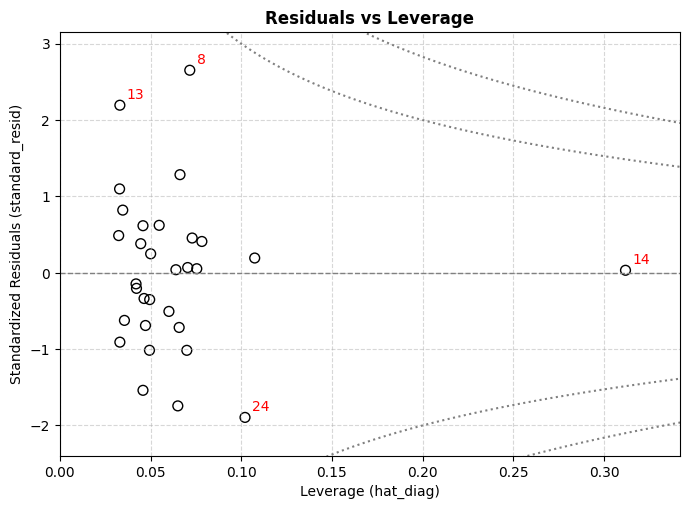

In [ ]:
plt.figure(figsize=(8, 5.5))

# Usar directamente hat_diag y standard_resid de df_influencia
plt.scatter(
    df_influencia["hat_diag"],
    df_influencia["standard_resid"],
    color="black",
    facecolors="none",
    s=50,
)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)

# Resaltar puntos particulares (ejemplo: observaciones 2, 13 y 26)
puntos_interes = [13, 8, 24, 14]
for i in puntos_interes:
    if i in df_influencia.index:
        plt.annotate(
            str(i),
            (df_influencia.loc[i, "hat_diag"], df_influencia.loc[i, "standard_resid"]),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=10,
            color="red",
        )

# Curvas teóricas de Distancia de Cook (0.5 y 1.0)
x_grid = np.linspace(0.001, df_influencia["hat_diag"].max() + 0.05, 100)
for cook_val in [0.5, 1.0]:
    y_cook = np.sqrt(cook_val * p * (1 - x_grid) / x_grid)
    plt.plot(
        x_grid,
        y_cook,
        color="gray",
        linestyle=":",
        label=f"Cook D={cook_val}" if cook_val == 0.5 else "",
    )
    plt.plot(x_grid, -y_cook, color="gray", linestyle=":")

plt.ylim(
    df_influencia["standard_resid"].min() - 0.5,
    df_influencia["standard_resid"].max() + 0.5,
)
plt.xlim(0, df_influencia["hat_diag"].max() + 0.03)

plt.title("Residuals vs Leverage", fontsize=12, fontweight="bold")
plt.xlabel("Leverage (hat_diag)")
plt.ylabel("Standardized Residuals (standard_resid)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## **Comparación de Modelos**

$$
\begin{array}{|l|c|c|c|c|c|c|c|c|c|c|}
\hline
\textbf{Modelo} & \textbf{N. Obs.} & \beta_0 & \beta_1 & \textbf{AIC} & \textbf{BIC} & R^2 & R^2_{\text{adj}} & \textbf{RMSE} & \textbf{MAE} & \textbf{MSE}\\ \hline
\textbf{Modelo 1} & 32 & -21.1863 & 1.0326 & 217.0 & 219.9 & 0.858 & 0.854 & 5.81 & 5.14 & 33.77 \\ \hline
\textbf{Modelo 2} & 31 & -18.1806 & 0.9944 & 210.4 & 213.2 & 0.819 & 0.813 & 5.50 & 4.95 & 30.24 \\ \hline
\end{array}
$$

### **Conclusiones:**

* El Modelo 1 es mejor si el objetivo es maximizar la proporción de variabilidad explicada de la variable dependiente, ya que presenta un coeficiente de determinación superior al del Modelo 2.

* El Modelo 2 es mejor si el objetivo es minimizar el error de pronóstico y la dispersión de los residuos, dado que registra métricas de error menores en todas las dimensiones en comparación con el Modelo 1.

* El Modelo 2 resulta mejor por el criterio de parsimonia y penalización de complejidad, al mostrar valores más bajos tanto en el AIC como en el BIC.